In [27]:
!pip install pyspark delta-spark -q

In [24]:
from google.colab import files

uploaded = files.upload()

In [30]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("ThemeParkOperations")
    .config(
        "spark.sql.extensions",
        "io.delta.sql.DeltaSparkSessionExtension"
    )
    .config(
        "spark.sql.catalog.spark_catalog",
        "org.apache.spark.sql.delta.catalog.DeltaCatalog"
    )
    .getOrCreate()
)

In [4]:
entries = spark.read.option("header", "true") \
    .option("inferSchema", "true") \
    .csv("/content/park_entries.csv")

maintenance = spark.read.option("header", "true") \
    .option("inferSchema", "true") \
    .csv("/content/attraction_maintenance.csv")

changes = spark.read.option("header", "true") \
    .option("inferSchema", "true") \
    .csv("/content/park_entry_changes.csv")

incremental = spark.read.option("header", "true") \
    .option("inferSchema", "true") \
    .csv("/content/park_entries_incremental.csv")

attractions = spark.read.json("/content/attractions.json")

In [5]:
display(entries)
display(attractions)
display(maintenance)
display(changes)
display(incremental)

DataFrame[entry_id: int, visitor_id: string, attraction_id: string, visit_date: date, entry_time: timestamp, wait_minutes: int, ride_minutes: int, ticket_type: string, ticket_price: double, status: string, booking_channel: string]

DataFrame[attraction_id: string, attraction_name: string, capacity_per_hour: bigint, category: string, features: array<string>, is_active: boolean, location: struct<section:string,zone:string>, min_height_cm: bigint, opened_year: bigint]

DataFrame[maintenance_id: string, attraction_id: string, maintenance_date: date, issue_type: string, downtime_minutes: int, maintenance_status: string]

DataFrame[entry_id: int, visitor_id: string, attraction_id: string, visit_date: date, entry_time: timestamp, wait_minutes: int, ride_minutes: int, ticket_type: string, ticket_price: double, status: string, booking_channel: string]

DataFrame[entry_id: int, visitor_id: string, attraction_id: string, visit_date: date, entry_time: timestamp, wait_minutes: int, ride_minutes: int, ticket_type: string, ticket_price: int, status: string, booking_channel: string]

In [6]:
print("Visitor Entries:", entries.count())
print("Attractions:", attractions.count())
print("Maintenance:", maintenance.count())
print("Changes:", changes.count())
print("Incremental Records:", incremental.count())

Visitor Entries: 121
Attractions: 10
Maintenance: 28
Changes: 10
Incremental Records: 12


In [7]:
entries.printSchema()
attractions.printSchema()
maintenance.printSchema()

root
 |-- entry_id: integer (nullable = true)
 |-- visitor_id: string (nullable = true)
 |-- attraction_id: string (nullable = true)
 |-- visit_date: date (nullable = true)
 |-- entry_time: timestamp (nullable = true)
 |-- wait_minutes: integer (nullable = true)
 |-- ride_minutes: integer (nullable = true)
 |-- ticket_type: string (nullable = true)
 |-- ticket_price: double (nullable = true)
 |-- status: string (nullable = true)
 |-- booking_channel: string (nullable = true)

root
 |-- attraction_id: string (nullable = true)
 |-- attraction_name: string (nullable = true)
 |-- capacity_per_hour: long (nullable = true)
 |-- category: string (nullable = true)
 |-- features: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- is_active: boolean (nullable = true)
 |-- location: struct (nullable = true)
 |    |-- section: string (nullable = true)
 |    |-- zone: string (nullable = true)
 |-- min_height_cm: long (nullable = true)
 |-- opened_year: long (nullable = tru

In [8]:
entries.createOrReplaceTempView("tp_entries_raw")
attractions.createOrReplaceTempView("tp_attractions")
maintenance.createOrReplaceTempView("tp_maintenance")
changes.createOrReplaceTempView("tp_entry_changes")
incremental.createOrReplaceTempView("tp_incremental")

In [9]:
result = spark.sql("""SELECT *FROM tp_entries_raw
WHERE status = 'Completed' AND ticket_price > 500""")

display(result)

DataFrame[entry_id: int, visitor_id: string, attraction_id: string, visit_date: date, entry_time: timestamp, wait_minutes: int, ride_minutes: int, ticket_type: string, ticket_price: double, status: string, booking_channel: string]

In [11]:
display(spark.sql("SELECT DISTINCT ticket_type FROM tp_entries_raw"))

DataFrame[ticket_type: string]

In [12]:
display(spark.sql("""
  SELECT
      a.attraction_name,
      SUM(e.ticket_price) AS total_revenue,
      COUNT(e.entry_id) AS completed_entries
  FROM tp_entries_raw e
  JOIN tp_attractions a
  ON e.attraction_id = a.attraction_id
  WHERE e.status = 'Completed'
  AND e.ticket_price > 0
  GROUP BY a.attraction_name
  ORDER BY total_revenue DESC
"""))


DataFrame[attraction_name: string, total_revenue: double, completed_entries: bigint]

In [13]:
display(spark.sql("""
  SELECT
      a.category,
      ROUND(AVG(e.wait_minutes), 2) AS average_wait
  FROM tp_entries_raw e
  JOIN tp_attractions a
  ON e.attraction_id = a.attraction_id
  WHERE e.wait_minutes >= 0
  GROUP BY a.category
  ORDER BY average_wait DESC
"""))

DataFrame[category: string, average_wait: double]

In [14]:
display(spark.sql("""
  SELECT
      a.location.zone AS zone,
      SUM(e.ticket_price) AS total_revenue
  FROM tp_entries_raw e
  JOIN tp_attractions a
  ON e.attraction_id = a.attraction_id
  WHERE e.status = 'Completed'
  AND e.ticket_price > 0
  GROUP BY a.location.zone
  ORDER BY total_revenue DESC
"""))

DataFrame[zone: string, total_revenue: double]

In [15]:
from pyspark.sql.functions import col

display(entries.filter(col("ticket_price").isNull()))

display(entries.filter(col("booking_channel").isNull()))

DataFrame[entry_id: int, visitor_id: string, attraction_id: string, visit_date: date, entry_time: timestamp, wait_minutes: int, ride_minutes: int, ticket_type: string, ticket_price: double, status: string, booking_channel: string]

DataFrame[entry_id: int, visitor_id: string, attraction_id: string, visit_date: date, entry_time: timestamp, wait_minutes: int, ride_minutes: int, ticket_type: string, ticket_price: double, status: string, booking_channel: string]

In [16]:
from pyspark.sql.functions import coalesce, lit

clean_entries = entries.withColumn(
    "booking_channel",
    coalesce(col("booking_channel"), lit("Unknown"))
)

display(clean_entries)

DataFrame[entry_id: int, visitor_id: string, attraction_id: string, visit_date: date, entry_time: timestamp, wait_minutes: int, ride_minutes: int, ticket_type: string, ticket_price: double, status: string, booking_channel: string]

In [17]:
invalid_data = clean_entries.filter(
    (col("wait_minutes") < 0) |
    (col("ride_minutes") <= 0) |
    (col("ticket_price") <= 0)
)

display(invalid_data)

DataFrame[entry_id: int, visitor_id: string, attraction_id: string, visit_date: date, entry_time: timestamp, wait_minutes: int, ride_minutes: int, ticket_type: string, ticket_price: double, status: string, booking_channel: string]

In [18]:
duplicates = entries.groupBy("entry_id").count().filter(
    col("count") > 1
)

display(duplicates)

deduplicated_entries = entries.dropDuplicates(["entry_id"])

display(deduplicated_entries)


DataFrame[entry_id: int, count: bigint]

DataFrame[entry_id: int, visitor_id: string, attraction_id: string, visit_date: date, entry_time: timestamp, wait_minutes: int, ride_minutes: int, ticket_type: string, ticket_price: double, status: string, booking_channel: string]

In [19]:
from pyspark.sql.functions import when

wait_df = clean_entries.filter(
    col("wait_minutes") >= 0
).withColumn(
    "wait_category",
    when(col("wait_minutes") <= 20, "Short")
    .when(col("wait_minutes") <= 45, "Medium")
    .otherwise("Long")
)

display(wait_df)

DataFrame[entry_id: int, visitor_id: string, attraction_id: string, visit_date: date, entry_time: timestamp, wait_minutes: int, ride_minutes: int, ticket_type: string, ticket_price: double, status: string, booking_channel: string, wait_category: string]

In [20]:
joined_df = clean_entries.join(
    attractions,
    "attraction_id",
    "left"
)

joined_df = joined_df.select(
    clean_entries["*"],
    attractions["attraction_name"],
    attractions["category"],
    attractions["location.zone"].alias("zone"),
    attractions["location.section"].alias("section"),
    attractions["features"]
)

display(joined_df)

DataFrame[entry_id: int, visitor_id: string, attraction_id: string, visit_date: date, entry_time: timestamp, wait_minutes: int, ride_minutes: int, ticket_type: string, ticket_price: double, status: string, booking_channel: string, attraction_name: string, category: string, zone: string, section: string, features: array<string>]

In [32]:
tp_entries_work = (
    entries
    .filter(
        (col("ticket_price") > 0) &
        (col("wait_minutes") >= 0) &
        (col("ride_minutes") > 0)
    )
    .dropDuplicates(["entry_id"])
)

In [33]:
tp_entries_work.write \
    .format("delta") \
    .mode("overwrite") \
    .save("/content/delta_tables/tp_entries_work")

tp_entries_work = spark.read \
    .format("delta") \
    .load("/content/delta_tables/tp_entries_work")

display(tp_entries_work)

Py4JJavaError: An error occurred while calling o430.save.
: org.apache.spark.SparkClassNotFoundException: [DATA_SOURCE_NOT_FOUND] Failed to find the data source: delta. Make sure the provider name is correct and the package is properly registered and compatible with your Spark version. SQLSTATE: 42K02
	at org.apache.spark.sql.errors.QueryExecutionErrors$.dataSourceNotFoundError(QueryExecutionErrors.scala:715)
	at org.apache.spark.sql.execution.datasources.DataSource$.lookupDataSource(DataSource.scala:705)
	at org.apache.spark.sql.execution.datasources.DataSource$.lookupDataSourceV2(DataSource.scala:764)
	at org.apache.spark.sql.classic.DataFrameWriter.lookupV2Provider(DataFrameWriter.scala:626)
	at org.apache.spark.sql.classic.DataFrameWriter.saveInternal(DataFrameWriter.scala:135)
	at org.apache.spark.sql.classic.DataFrameWriter.save(DataFrameWriter.scala:118)
	at java.base/jdk.internal.reflect.NativeMethodAccessorImpl.invoke0(Native Method)
	at java.base/jdk.internal.reflect.NativeMe

In [34]:
from delta import configure_spark_with_delta_pip
from pyspark.sql import SparkSession

builder = (
    SparkSession.builder
    .appName("ThemeParkOperations")
    .config("spark.sql.extensions",
            "io.delta.sql.DeltaSparkSessionExtension")
    .config("spark.sql.catalog.spark_catalog",
            "org.apache.spark.sql.delta.catalog.DeltaCatalog")
)

spark = configure_spark_with_delta_pip(builder).getOrCreate()

In [35]:

from delta.tables import DeltaTable

changes.write \
    .format("delta") \
    .mode("overwrite") \
    .save("/content/delta_tables/tp_entry_changes")

delta_target = DeltaTable.forPath(
    spark,
    "/content/delta_tables/tp_entries_work"
)

delta_target.alias("target").merge(
    changes.alias("source"),
    "target.entry_id = source.entry_id"
).whenMatchedUpdateAll() \
 .whenNotMatchedInsertAll() \
 .execute()

display(
    spark.read.format("delta")
    .load("/content/delta_tables/tp_entries_work")
)


Py4JJavaError: An error occurred while calling o437.save.
: org.apache.spark.SparkClassNotFoundException: [DATA_SOURCE_NOT_FOUND] Failed to find the data source: delta. Make sure the provider name is correct and the package is properly registered and compatible with your Spark version. SQLSTATE: 42K02
	at org.apache.spark.sql.errors.QueryExecutionErrors$.dataSourceNotFoundError(QueryExecutionErrors.scala:715)
	at org.apache.spark.sql.execution.datasources.DataSource$.lookupDataSource(DataSource.scala:705)
	at org.apache.spark.sql.execution.datasources.DataSource$.lookupDataSourceV2(DataSource.scala:764)
	at org.apache.spark.sql.classic.DataFrameWriter.lookupV2Provider(DataFrameWriter.scala:626)
	at org.apache.spark.sql.classic.DataFrameWriter.saveInternal(DataFrameWriter.scala:135)
	at org.apache.spark.sql.classic.DataFrameWriter.save(DataFrameWriter.scala:118)
	at java.base/jdk.internal.reflect.NativeMethodAccessorImpl.invoke0(Native Method)
	at java.base/jdk.internal.reflect.NativeMe

In [36]:
from delta.tables import DeltaTable

delta_table = DeltaTable.forPath(
    spark,
    "/content/delta_tables/tp_entries_work"
)

display(delta_table.history())

previous_version = spark.read \
    .format("delta") \
    .option("versionAsOf", 0) \
    .load("/content/delta_tables/tp_entries_work")

display(previous_version)


TypeError: 'JavaPackage' object is not callable

In [38]:
tp_completed_view = spark.sql("""
SELECT
    e.entry_id,
    e.visitor_id,
    a.attraction_name,
    e.ticket_type,
    e.ticket_price,
    e.wait_minutes
FROM tp_entries_work e
JOIN tp_attractions a
ON e.attraction_id = a.attraction_id
WHERE e.status = 'Completed'
""")

tp_completed_view.createOrReplaceTempView(
    "tp_completed_view"
)

display(tp_completed_view)

Py4JJavaError: An error occurred while calling o31.sql.
: org.apache.spark.SparkException: Cannot find catalog plugin class for catalog 'spark_catalog': org.apache.spark.sql.delta.catalog.DeltaCatalog.
	at org.apache.spark.sql.errors.QueryExecutionErrors$.catalogPluginClassNotFoundForCatalogError(QueryExecutionErrors.scala:1833)
	at org.apache.spark.sql.connector.catalog.Catalogs$.load(Catalogs.scala:70)
	at org.apache.spark.sql.connector.catalog.CatalogManager.loadV2SessionCatalog(CatalogManager.scala:70)
	at org.apache.spark.sql.connector.catalog.CatalogManager.$anonfun$v2SessionCatalog$1(CatalogManager.scala:90)
	at scala.collection.mutable.HashMap.getOrElseUpdate(HashMap.scala:469)
	at org.apache.spark.sql.connector.catalog.CatalogManager.v2SessionCatalog(CatalogManager.scala:90)
	at org.apache.spark.sql.connector.catalog.CatalogManager.catalog(CatalogManager.scala:54)
	at org.apache.spark.sql.connector.catalog.CatalogManager.currentCatalog(CatalogManager.scala:132)
	at org.apache.

In [39]:
from pyspark.sql.functions import col

stream_df = spark.readStream \
    .format("rate") \
    .option("rowsPerSecond", 5) \
    .load()

visitor_stream = stream_df.withColumn(
    "visitor_event_id",
    col("value")
).withColumn(
    "simulated_wait_minutes",
    (col("value") % 60).cast("int")
)

filtered_stream = visitor_stream.filter(
    col("simulated_wait_minutes") > 30
)

query = filtered_stream.writeStream \
    .format("console") \
    .outputMode("append") \
    .option("checkpointLocation",
            "/content/checkpoints/stream1") \
    .start()

query.awaitTermination(30)
query.stop()

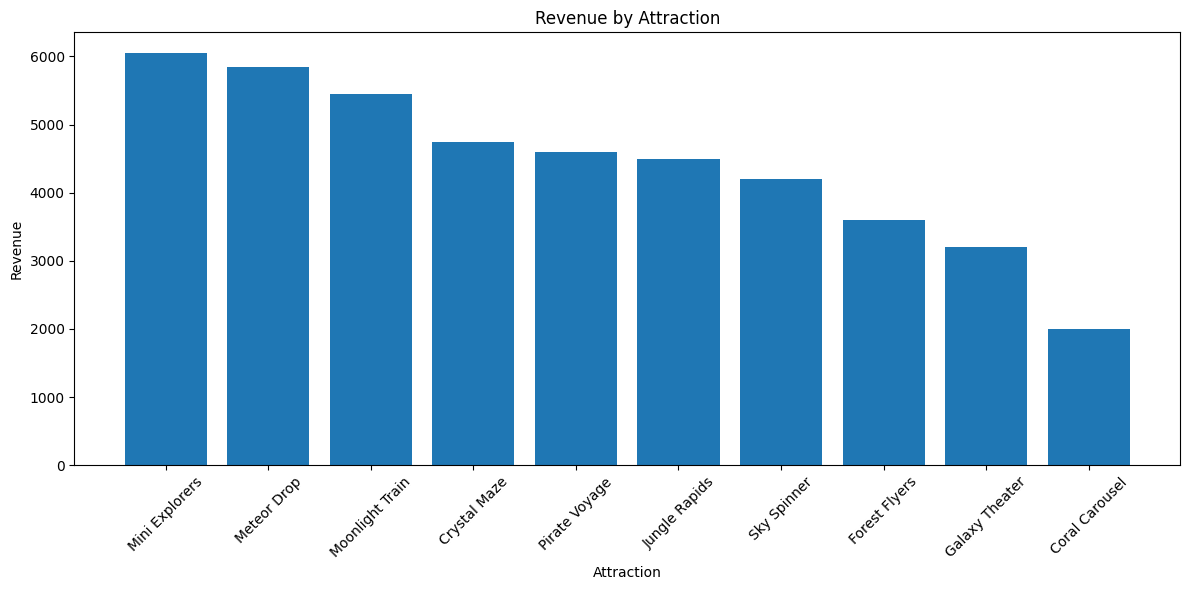

In [40]:
import matplotlib.pyplot as plt

revenue_df = spark.sql("""
SELECT
    a.attraction_name,
    SUM(e.ticket_price) AS total_revenue
FROM tp_entries_raw e
JOIN tp_attractions a
ON e.attraction_id = a.attraction_id
WHERE e.status = 'Completed'
AND e.ticket_price > 0
GROUP BY a.attraction_name
ORDER BY total_revenue DESC
""").toPandas()

plt.figure(figsize=(12, 6))
plt.bar(
    revenue_df["attraction_name"],
    revenue_df["total_revenue"]
)
plt.xticks(rotation=45)
plt.xlabel("Attraction")
plt.ylabel("Revenue")
plt.title("Revenue by Attraction")
plt.tight_layout()
plt.show()

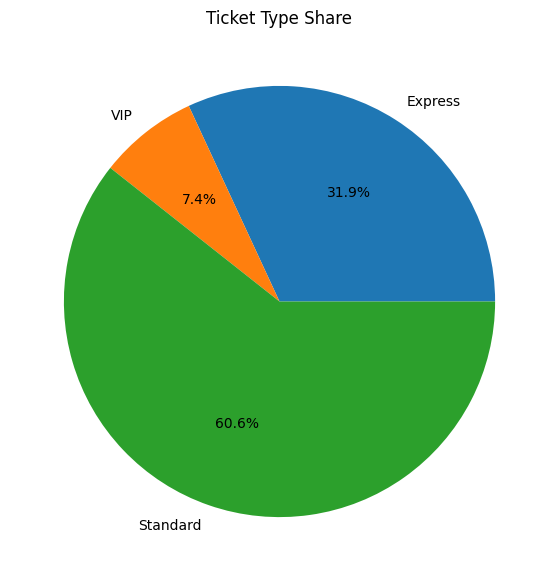

In [41]:
ticket_df = spark.sql("""
SELECT ticket_type, COUNT(*) AS total
FROM tp_entries_raw
WHERE status = 'Completed'
GROUP BY ticket_type
""").toPandas()

plt.figure(figsize=(7, 7))
plt.pie(
    ticket_df["total"],
    labels=ticket_df["ticket_type"],
    autopct="%1.1f%%"
)
plt.title("Ticket Type Share")
plt.show()

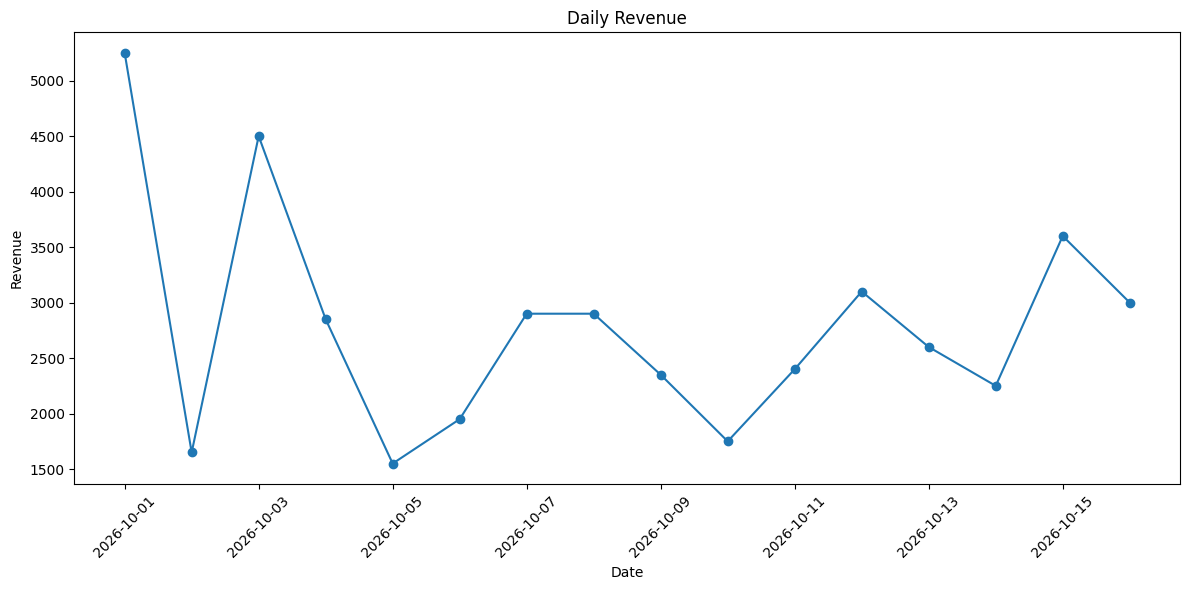

In [42]:
daily_df = spark.sql("""
SELECT
    TO_DATE(visit_date) AS visit_date,
    SUM(ticket_price) AS daily_revenue
FROM tp_entries_raw
WHERE status = 'Completed'
AND ticket_price > 0
GROUP BY TO_DATE(visit_date)
ORDER BY visit_date
""").toPandas()

plt.figure(figsize=(12, 6))
plt.plot(
    daily_df["visit_date"],
    daily_df["daily_revenue"],
    marker="o"
)
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.title("Daily Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

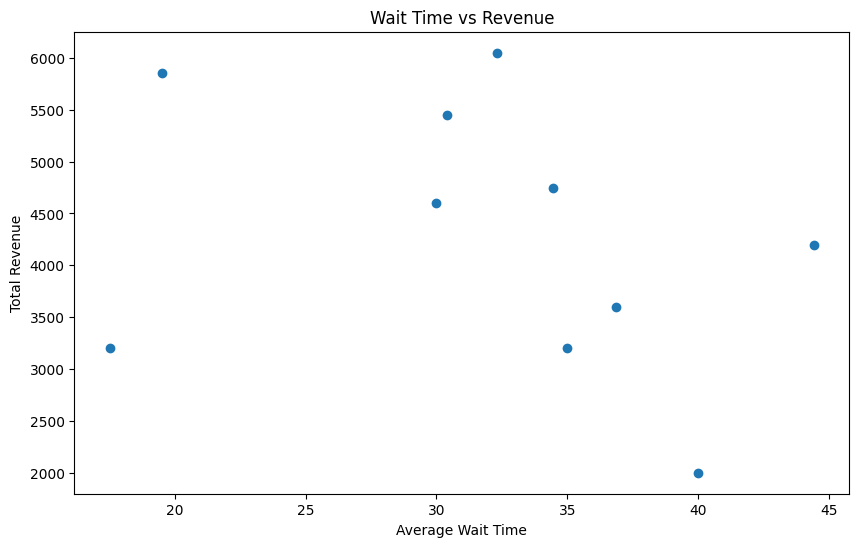

In [43]:
scatter_df = spark.sql("""
SELECT
    a.attraction_name,
    AVG(e.wait_minutes) AS average_wait,
    SUM(e.ticket_price) AS total_revenue
FROM tp_entries_raw e
JOIN tp_attractions a
ON e.attraction_id = a.attraction_id
WHERE e.status = 'Completed'
AND e.wait_minutes >= 0
AND e.ticket_price > 0
GROUP BY a.attraction_name
""").toPandas()

plt.figure(figsize=(10, 6))
plt.scatter(
    scatter_df["average_wait"],
    scatter_df["total_revenue"]
)

plt.xlabel("Average Wait Time")
plt.ylabel("Total Revenue")
plt.title("Wait Time vs Revenue")
plt.show()